# Stage-1 gate: is this mouth healthy, or does it have an issue? (DenseNet-121 vs DINOv2 ViT-B/14)

**Pipeline.** Every photo goes through this binary classifier first. Only photos it flags go on to the YOLO detector
(stage 2, `models/yolo_caries/scripts/Aiden/`), which says *which* condition and *where*. A photo the gate misses never
reaches YOLO, so the gate is tuned to **catch issues** (threshold = catch 95% of issues on the clean val set).

**Data.** Daniel's `oral_dataset` (`data/raw/oral_dataset/`, the cleaned 33,843-image release from his
`qwen_clean_and_label.ipynb`), target `has_issue`, and his binary split (`manifests/Daniel/binary_classifier_split.csv`):
train, val, test, plus two **cross-source** sets (`xsrc_val`, `xsrc_test`) carved out of the non-Roboflow training photos.

**This notebook explains and checks; the scripts do the work.** Training is in `scripts/Aiden/train.py`, the comparison
report and graphs in `scripts/Aiden/report.py`. The notebook imports them instead of copying their code, so the two can't
drift apart. Set `RETRAIN = True` to retrain both models from here (about 1-2 h each on an RTX 4060); otherwise it reads
the saved results in `results/Aiden/`.

Sections: 1 setup · 2 the data · 3 leakage · 4 the source problem · 5 training method · 6 results · 7 results per source
· 8 most confident mistakes · 9 Grad-CAM · 10 experiment log and decision

## 1. Setup

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from PIL import Image
from IPython.display import Image as Show, Markdown, display

REPO = Path.cwd().resolve()
while not (REPO / "models").is_dir():
    REPO = REPO.parent
sys.path[:0] = [str(REPO / "models/classifier/scripts/Aiden"), str(REPO / "models/classifier/src")]
import train, report, multilabel        # the same code the scripts run
%matplotlib inline

RETRAIN = False                         # True: retrain both models (overwrites results/Aiden/<arch>/)
ARCHS = {"densenet121": "--lr 1e-4", "dinov2_vitb14": ""}   # the learning rates used in the comparison
DATA, RESULTS, TARGET, CONDITIONS = train.DATA, train.RESULTS, train.TARGET, train.CONDITIONS
FIG = RESULTS / "figures"
pd.set_option("display.width", 160)

## 2. The data

In [2]:
df = pd.read_csv(DATA / "labels.csv", keep_default_na=False)
df = df.merge(pd.read_csv(train.LEAKS)[["md5", "leaked"]], on="md5", how="left")
df["leaked"] = df.leaked.fillna(False).astype(bool)
print(f"{len(df)} images, {df.group.nunique()} photo groups (copies of one photo share a group)")
display(pd.crosstab(df.split, df[TARGET].map({0: "healthy", 1: "has an issue"}), margins=True))
print("images with each condition, per split (one image can have several):")
display(df.groupby("split")[CONDITIONS].sum().T[["train", "val", "test"]])

# Has the dataset changed since the saved models were trained?
for arch in ARCHS:
    m = RESULTS / arch / "metrics.json"
    if m.exists():
        n = json.loads(m.read_text())["n_train"]
        same = n == (df.split == "train").sum()
        print(f"{arch}: trained on {n} training images; this labels.csv has {(df.split == 'train').sum()}"
              + ("" if same else "  <-- DIFFERENT: retrain (and re-run find_leaks.py) before trusting section 6"))

33843 images, 16640 photo groups (copies of one photo share a group)


has_issue,has an issue,healthy,All
split,,,
test,2447,599,3046
train,23265,4591,27856
val,2301,640,2941
All,28013,5830,33843


images with each condition, per split (one image can have several):


split,train,val,test
Calculus,3587,429,415
Caries,10749,845,811
Hypodontia,2500,288,397
Mouth_Ulcer,4698,550,568
Tooth_Discoloration,7914,868,885


densenet121: trained on 25524 training images; this labels.csv has 27856  <-- DIFFERENT: retrain (and re-run find_leaks.py) before trusting section 6
dinov2_vitb14: trained on 25524 training images; this labels.csv has 27856  <-- DIFFERENT: retrain (and re-run find_leaks.py) before trusting section 6


## 3. Leakage: copies of training photos in val and test

Roboflow's export holds many cropped, rotated and recoloured copies of each photo, and they were spread over train, val
and test. A model can then score well on test by *remembering* photos. `scripts/Aiden/find_leaks.py` marks every val/test
image with a copy in train (DINOv2 proposes similar pairs, SIFT keypoint matching confirms them). Those are left out of
the **clean** val and test sets; the threshold and the headline scores use only the clean sets.

images  copies_of_train  share_leaked
split has_issue                                       
test  0             599                0         0.000
      1            2447             2269         0.927
val   0             640                0         0.000
      1            2301             2089         0.908

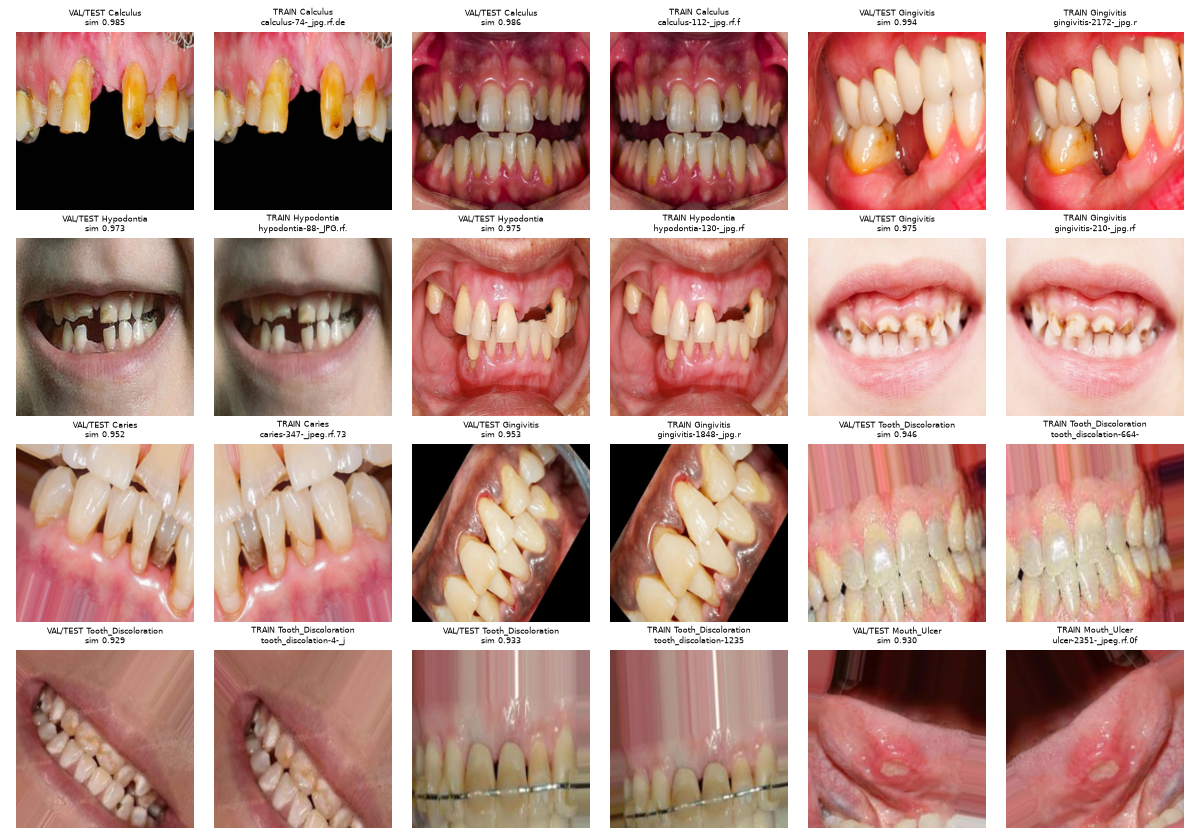

In [3]:
t = df[df.split != "train"].groupby(["split", TARGET]).leaked.agg(images="size", copies_of_train="sum")
t["share_leaked"] = (t.copies_of_train / t.images).round(3)
display(t)
display(Show(FIG / "roboflow_split_leak_pairs.png", width=900))   # examples of matched pairs

## 4. The source problem: what the clean test can and cannot show

The table below is the clean test set by *where each photo came from*. Every image with an issue comes from
`roboflow_oral` and every healthy image from another source. So the clean test can't tell apart a model that recognises
disease from one that recognises "a Roboflow-style photo" (its cropping, colour, resolution, compression): both would
score the same. Training has the same pattern (all Mendeley photos are healthy, all Roboflow photos have an issue).

This is a limitation of the data, not of either model, and it applies to both. The fix is Daniel's **cross-source
test** (second table): issue and healthy photos from the *same* non-Roboflow sources (dentalai, kaggle_oral, zenodo,
external), none of them used in training. A model that only learned the Roboflow look fails there. Daniel's gate is
scored on the same images, so it is also the fairest comparison with his model. Grad-CAM (section 9) shows where the
models look.

In [4]:
clean_test = df[(df.split == "test") & ~df.leaked]
display(pd.crosstab(clean_test.dataset, clean_test[TARGET].map({0: "healthy", 1: "has an issue"}), margins=True))
roles = df.merge(pd.read_csv(train.ROLES)[["md5", "role"]], on="md5")
x = roles[roles.role == "xsrc_test"]
print("cross-source test (xsrc_test):")
display(pd.crosstab(x.dataset, x[TARGET].map({0: "healthy", 1: "has an issue"}), margins=True))
tr = roles[roles.role == "train"]
print("training set (Daniel's train minus the two cross-source sets):")
display(pd.crosstab(tr.dataset, tr[TARGET].map({0: "healthy", 1: "has an issue"})))

has_issue,has an issue,healthy,All
dataset,,,
dentalai,0,92,92
external_clean,0,6,6
kaggle_oral,0,60,60
mendeley_noncaries,0,435,435
roboflow_oral,178,0,178
zenodo,0,6,6
All,178,599,777


cross-source test (xsrc_test):


has_issue,has an issue,healthy,All
dataset,,,
dentalai,187,92,279
external_clean,41,7,48
kaggle_oral,94,15,109
mendeley_noncaries,0,454,454
zenodo,270,6,276
All,592,574,1166


training set (Daniel's train minus the two cross-source sets):


has_issue,has an issue,healthy
dataset,,
dentalai,1122,553
external_clean,244,36
kaggle_oral,566,90
mendeley_noncaries,0,2726
roboflow_oral,18529,0
zenodo,1620,38


## 5. Training method (`train.py`)

| Choice | Why |
|---|---|
| DenseNet-121 (ImageNet, 8M params) vs DINOv2 ViT-B/14 (self-supervised, 86M) | a strong CNN baseline against a modern foundation model |
| One sigmoid output, BCE with `pos_weight` | binary target; `pos_weight` balances healthy vs issue |
| Label smoothing 0.05 | some labels come from Qwen and are wrong (section 8 shows examples) |
| Every photo group equally likely per epoch | some photos have 200 copies in train; they would outvote the rest |
| Augmentation: crop, flip, rotate, brightness/contrast; **no hue/saturation** | tooth discolouration *is* a colour |
| AdamW, one-cycle cosine schedule, fixed 10 epochs | no epoch is picked on val, so val stays unbiased for the threshold |
| DINOv2: layer-wise LR decay 0.75 | lower layers hold general features, so they change less |
| Flip test-time augmentation | average of the photo and its mirror image |
| Train on Daniel's `train` role (cross-source sets held out) | so the cross-source test is never seen in training |
| Platt calibration + threshold on clean val + cross-source val | threshold = highest that still catches 95% of issues in each, so it isn't tuned only on Roboflow photos |

In [5]:
if RETRAIN:
    for arch, extra in ARCHS.items():
        cmd = [sys.executable, str(REPO / "models/classifier/scripts/Aiden/train.py"), "--arch", arch, *extra.split()]
        print(" ".join(cmd)); subprocess.run(cmd, check=True, cwd=REPO)
else:
    print("RETRAIN = False: using the saved results in", RESULTS)

RETRAIN = False: using the saved results in C:\Users\aiden\Downloads\AI WIU\Deep-Learning-WIU\models\classifier\results\Aiden


## 6. Results

Clean test unless the row says otherwise. Daniel's gate is only scored here on the cross-source test.

,DenseNet-121,DINOv2 ViT-B/14,Daniel (mobilenet_v3_large)
AUROC (95% CI),0.9946 (0.9896-0.9983),0.9957 (0.9909-0.9995),
AP,0.970,0.956,
sensitivity (95% CI),0.989 (0.970-1.000),0.989 (0.971-1.000),
specificity,0.960,0.972,
issues missed,2 of 178,2 of 178,
false alarms,24 of 599,17 of 599,
threshold,0.631,0.855,
"AUROC, full test (leaky)",0.9944,0.9953,
CROSS-SOURCE TEST AUROC (95% CI),0.9798 (0.9711-0.9872),0.9839 (0.9757-0.9903),0.9797
cross-source sensitivity,0.936,0.936,0.936


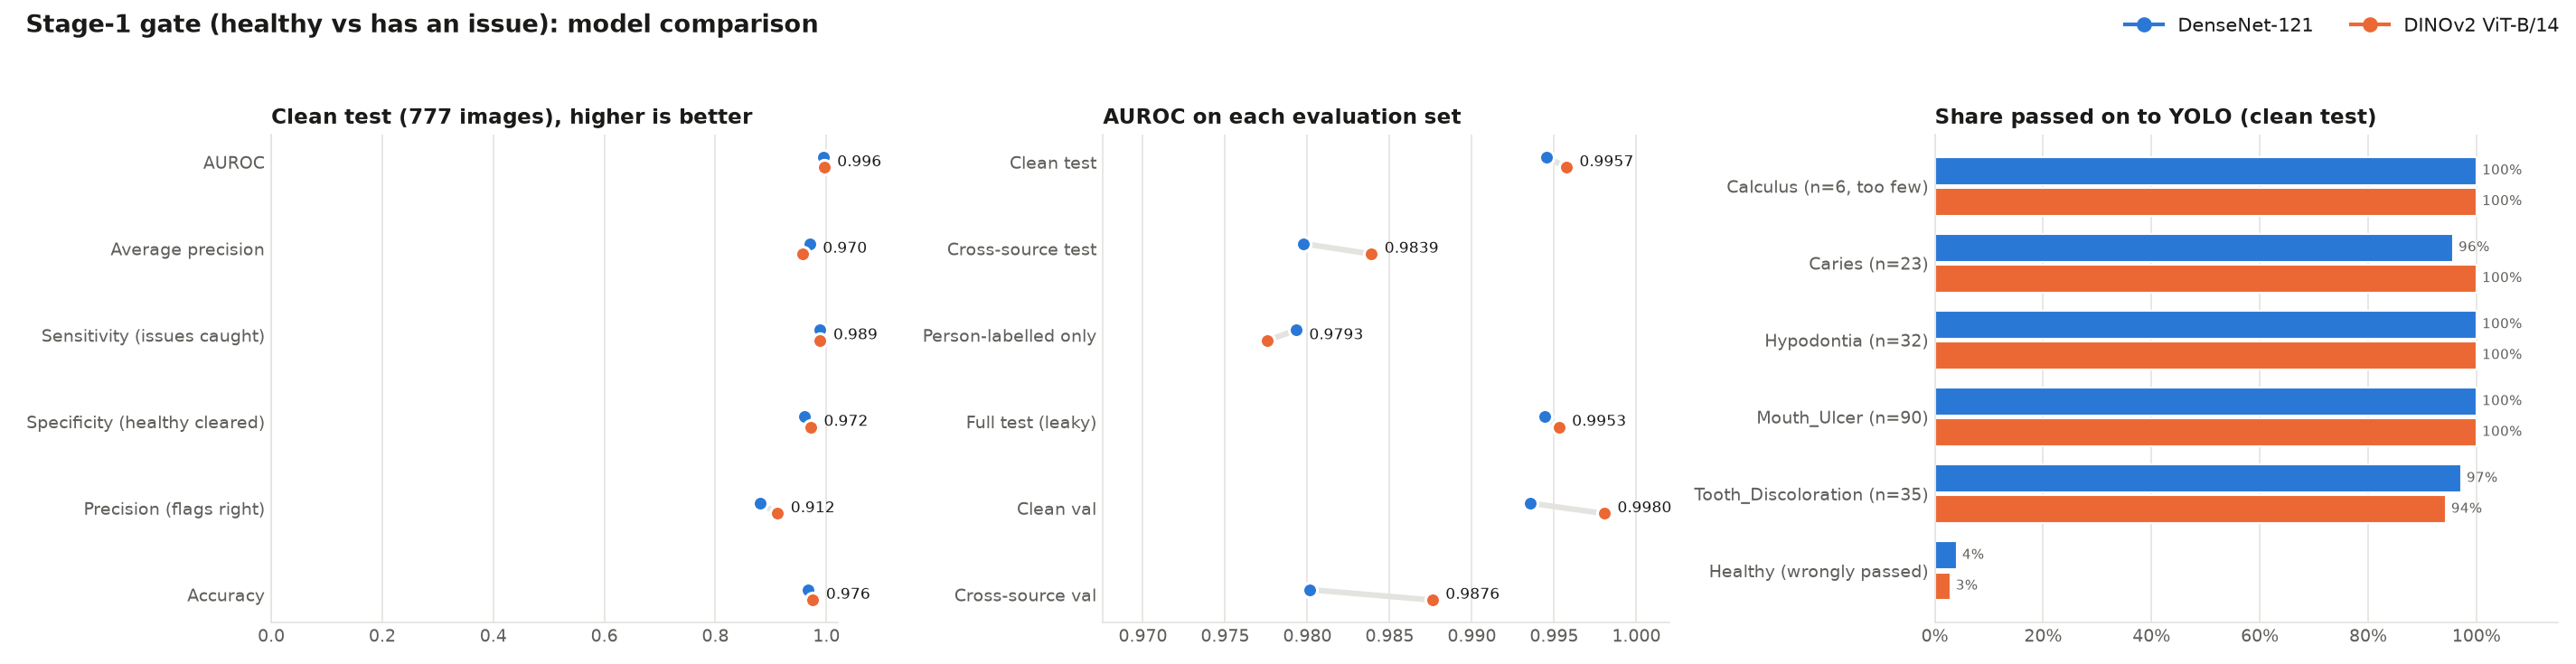

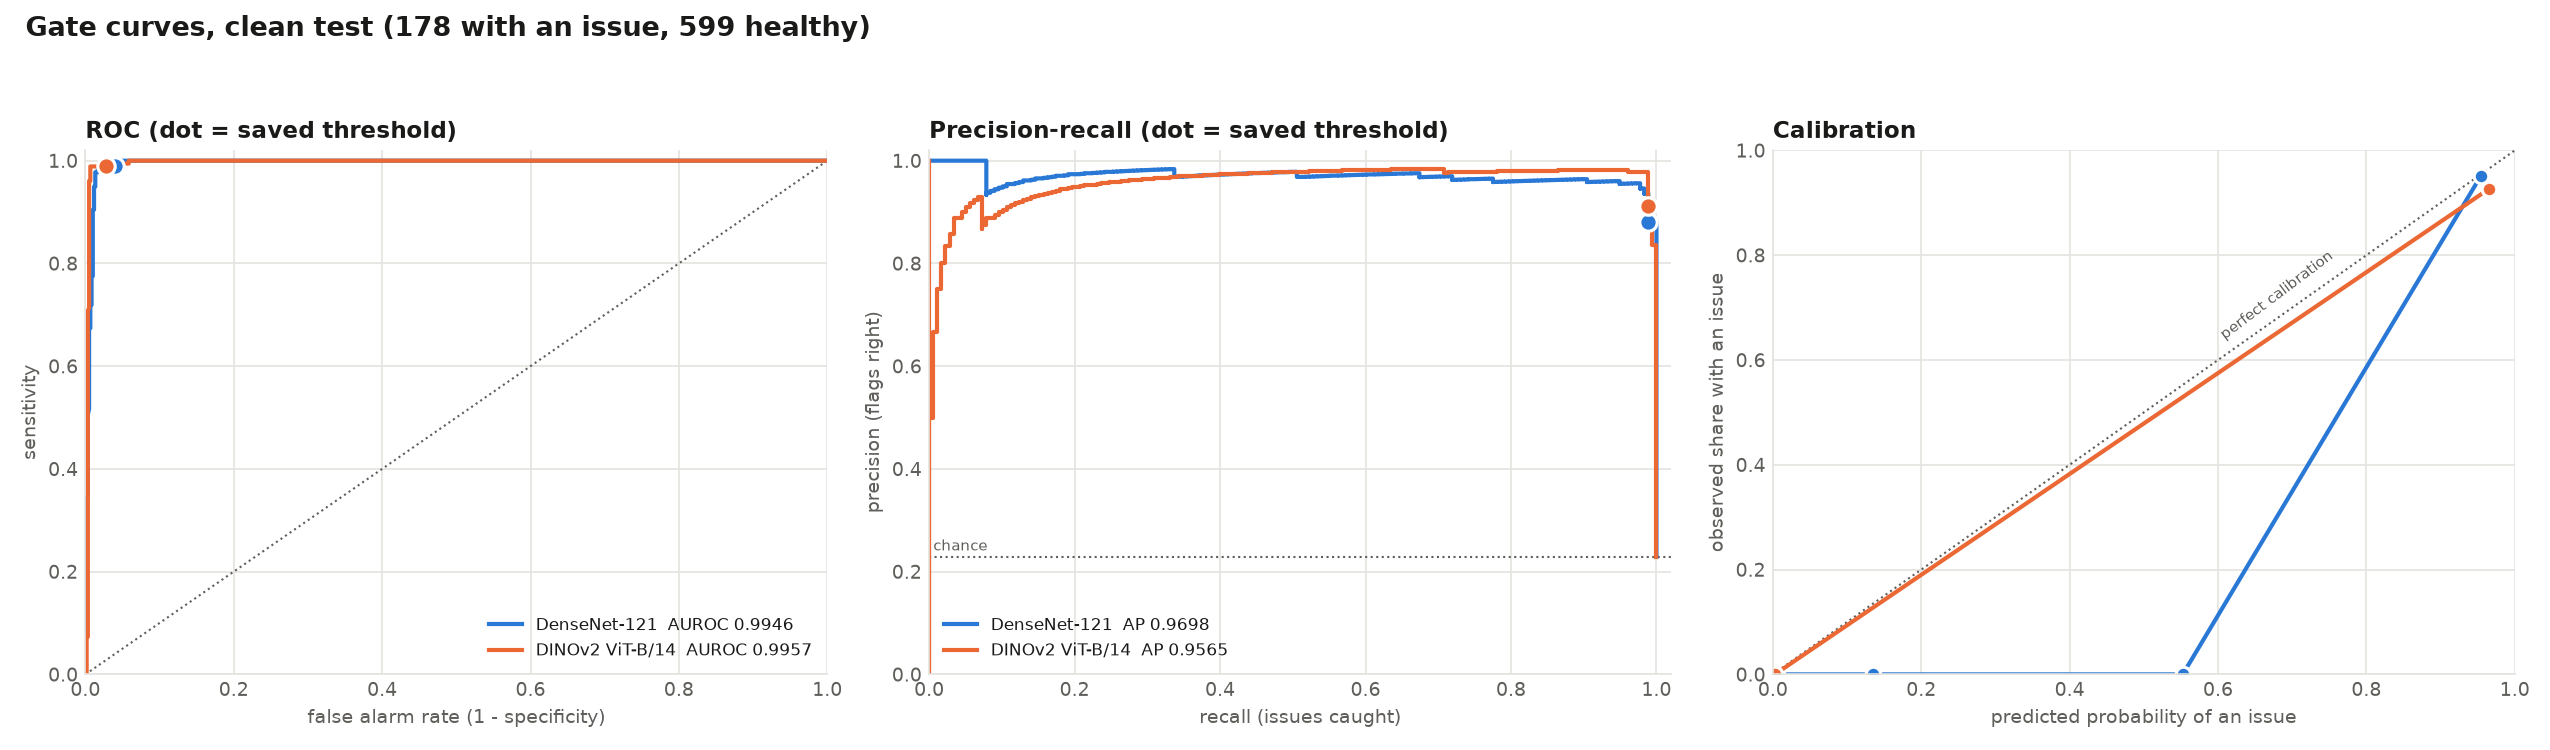

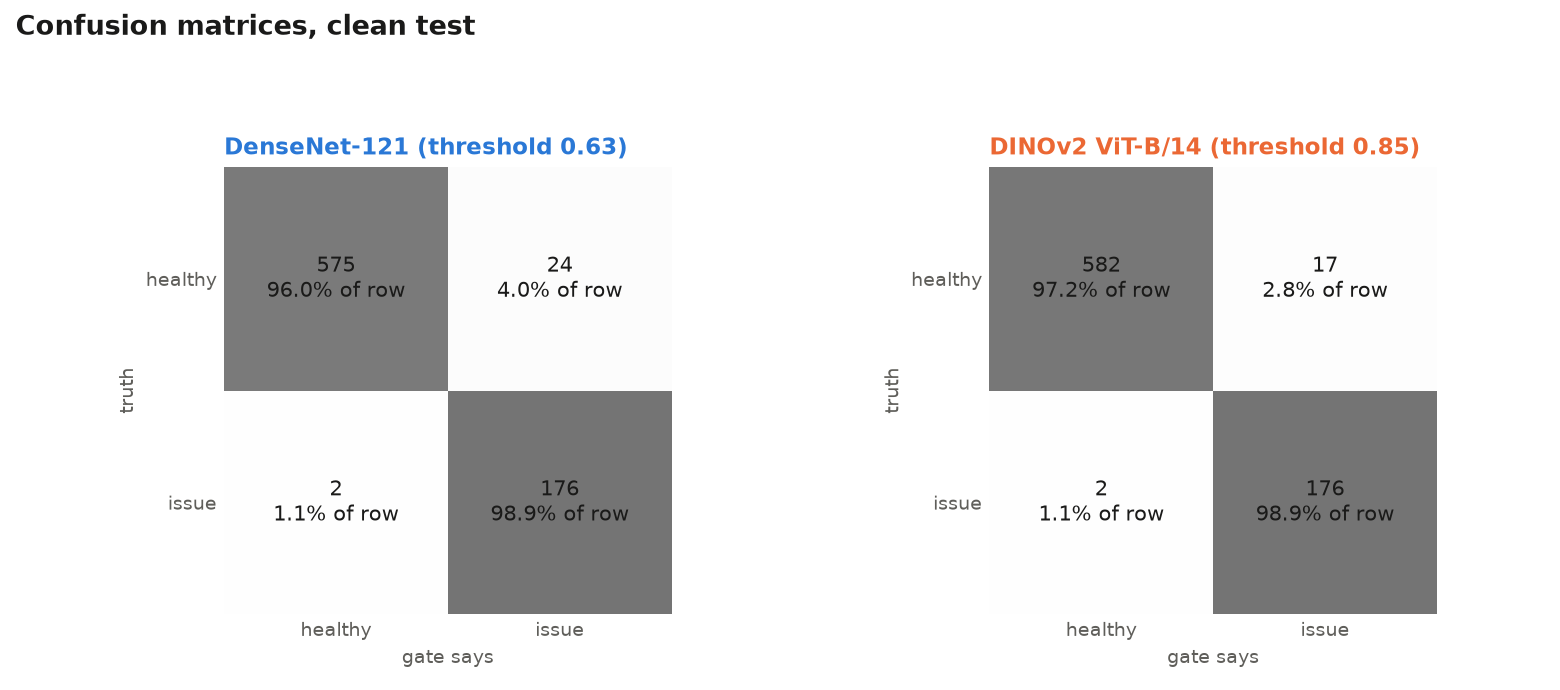

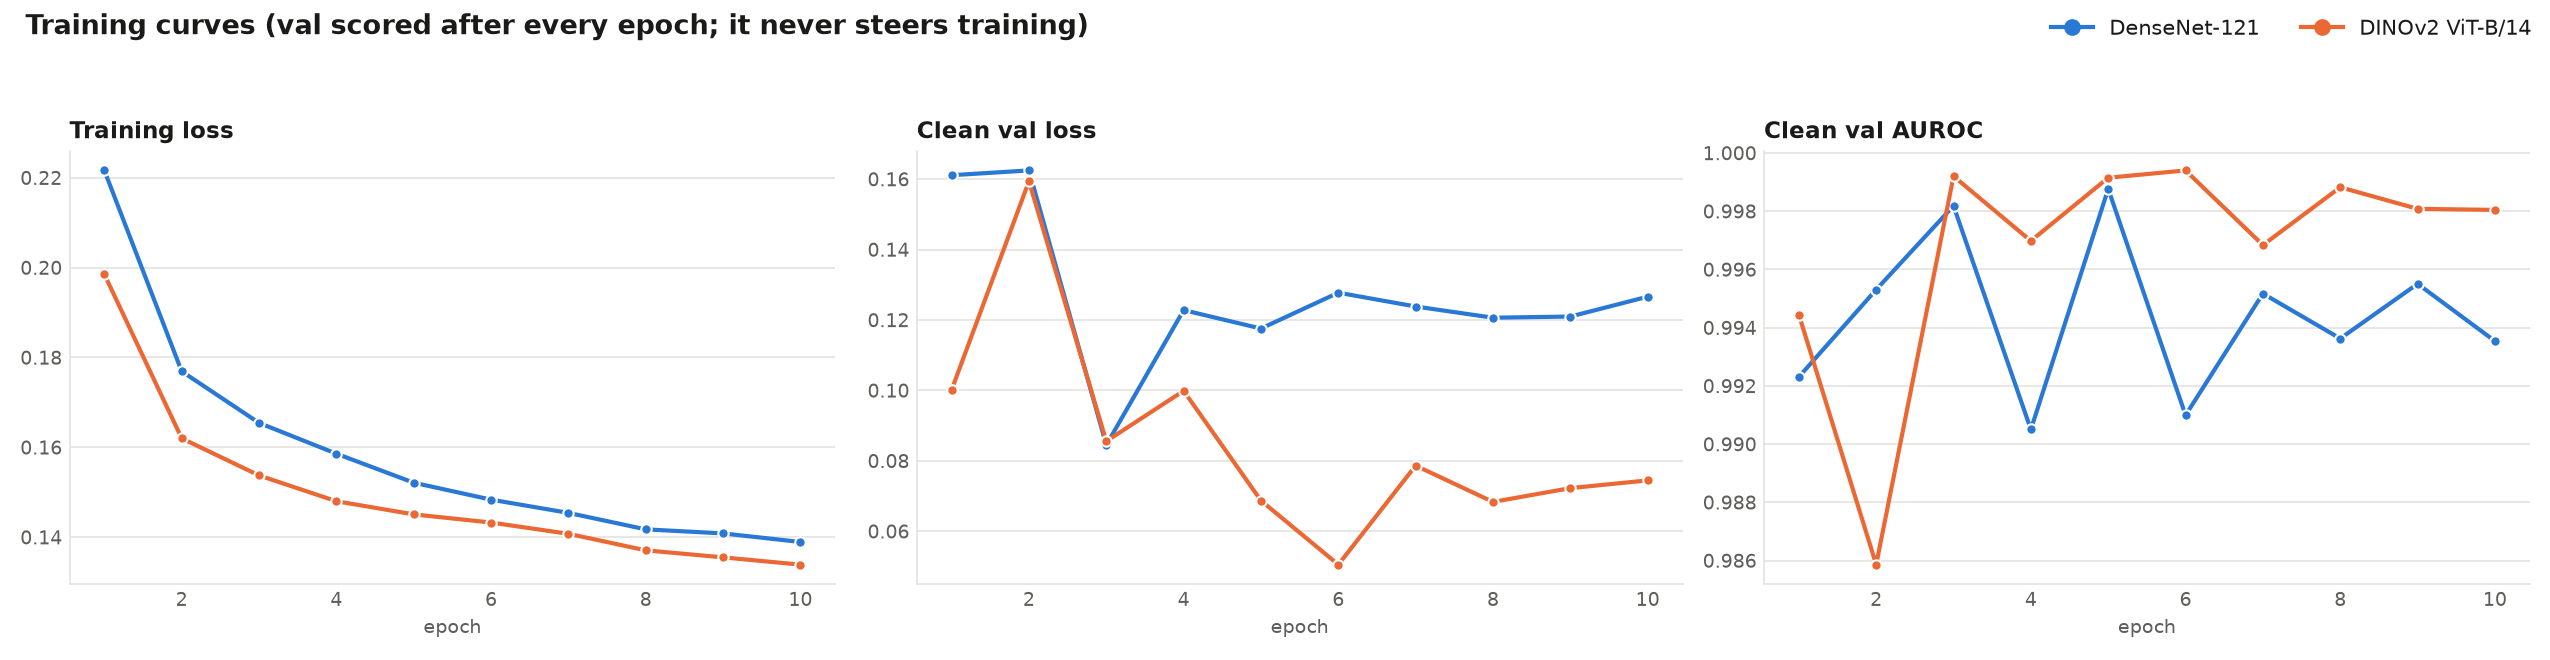

In [6]:
runs = {a: json.loads((RESULTS / a / "metrics.json").read_text()) for a in ARCHS if (RESULTS / a / "metrics.json").exists()}
rows = {}
for a, m in runs.items():
    rows[m["name"]] = {
        "AUROC (95% CI)": f"{m['auroc']:.4f} ({m['auroc_ci'][0]:.4f}-{m['auroc_ci'][1]:.4f})",
        "AP": f"{m['ap']:.3f}",
        "sensitivity (95% CI)": f"{m['sensitivity']:.3f} ({m['sensitivity_ci'][0]:.3f}-{m['sensitivity_ci'][1]:.3f})",
        "specificity": f"{m['specificity']:.3f}",
        "issues missed": f"{m['confusion']['fn']} of {m['n_issue']}",
        "false alarms": f"{m['confusion']['fp']} of {m['n_healthy']}",
        "threshold": f"{m['threshold']:.3f}",
        "AUROC, full test (leaky)": f"{m['full_test']['auroc']:.4f}",
        "CROSS-SOURCE TEST AUROC (95% CI)": f"{m['xsrc_test']['auroc']:.4f} ({m['xsrc_test']['auroc_ci'][0]:.4f}-{m['xsrc_test']['auroc_ci'][1]:.4f})",
        "cross-source sensitivity": f"{m['xsrc_test']['sensitivity']:.3f}",
        "cross-source specificity": f"{m['xsrc_test']['specificity']:.3f}",
        **{f"reaches YOLO: {c}": f"{v['share']:.0%} of {v['n']}" for c, v in m["passed_to_yolo"].items()}}
d = report.daniel()
if d:
    rows[f"Daniel ({d['backbone']})"] = {"CROSS-SOURCE TEST AUROC (95% CI)": f"{d['auroc']:.4f}",
                                         "cross-source sensitivity": f"{d['sensitivity']:.3f}", "cross-source specificity": f"{d['specificity']:.3f}"}
print("Clean test unless the row says otherwise. Daniel's gate is only scored here on the cross-source test.")
display(pd.DataFrame(rows).fillna(""))
report.write_all()                       # rebuilds comparison_report.txt and the graphs from the saved results
for f in report.FIGURES:
    display(Show(FIG / f, width=1000))

**Reading the graphs.** The ROC curves hug the top-left corner: near perfect, which with the source problem (section 4)
is a warning, not a win: the cross-source test is the harder, fairer one (AUROC about 0.98 for both models, 0.9797 for
Daniel's gate; within a single source it falls to 0.86-0.99). Dips at the start of a precision-recall curve come from a few healthy-labelled photos the model
is very sure about (section 8: several are mislabelled). The calibration bins between 0.2 and 0.8 hold only a few dozen
photos, so their zigzag is mostly noise. The training-curve axes are zoomed in: AUROC moves within about 0.01.

## 7. Results per source: disease or photo style?

**Within one source** (top table) both classes are the same kind of photo, so a high AUROC there can only come from the
mouth itself. This is the cleanest test of "disease, not source". Sources with only a handful of healthy photos (zenodo,
external) give unstable numbers. The bottom table is the false-alarm rate on each healthy source of the clean test.

In [7]:
within = pd.DataFrame({m["name"]: {f"{s} ({v['n_issue']} issue / {v['n_healthy']} healthy)": v["auroc"]
                                   for s, v in m["xsrc_per_source"].items()} for m in runs.values()})
print("cross-source test, AUROC within each source:")
display(within.round(4))
per = []
for a, m in runs.items():
    p = pd.read_csv(RESULTS / a / "test_predictions.csv")
    p["flagged"] = p.p_issue >= m["threshold"]
    g = p.groupby(["dataset", TARGET]).agg(images=("flagged", "size"), flagged=("flagged", "mean"))
    per.append(g.flagged.rename(m["name"]))
per = pd.concat([g.images] + per, axis=1).reset_index()
per["what the share means"] = np.where(per[TARGET] == 1, "issues caught", "false alarms")
print("clean test, per source:")
display(per.round(3))

cross-source test, AUROC within each source:


,DenseNet-121,DINOv2 ViT-B/14
dentalai (187 issue / 92 healthy),0.8971,0.9048
external_clean (41 issue / 7 healthy),0.9303,0.9861
kaggle_oral (94 issue / 15 healthy),0.9787,0.9716
mendeley_noncaries (0 issue / 454 healthy),NaN,NaN
zenodo (270 issue / 6 healthy),0.8772,0.8586


clean test, per source:


,dataset,has_issue,images,DenseNet-121,DINOv2 ViT-B/14,what the share means
0,dentalai,0,92,0.152,0.109,false alarms
1,external_clean,0,6,0.000,0.167,false alarms
2,kaggle_oral,0,60,0.150,0.100,false alarms
3,mendeley_noncaries,0,435,0.002,0.000,false alarms
4,roboflow_oral,1,178,0.989,0.989,issues caught
5,zenodo,0,6,0.000,0.000,false alarms


## 8. Most confident mistakes

The healthy-labelled photos each model is most sure have an issue, and the issue photos it is most sure are healthy,
over the clean and cross-source tests together. Look
at them before blaming the model: several "healthy" labels come from Qwen or from a source folder name and are wrong
(e.g. a gum swelling with bleeding, labelled Normal). Report these to Daniel so the dataset can be fixed.

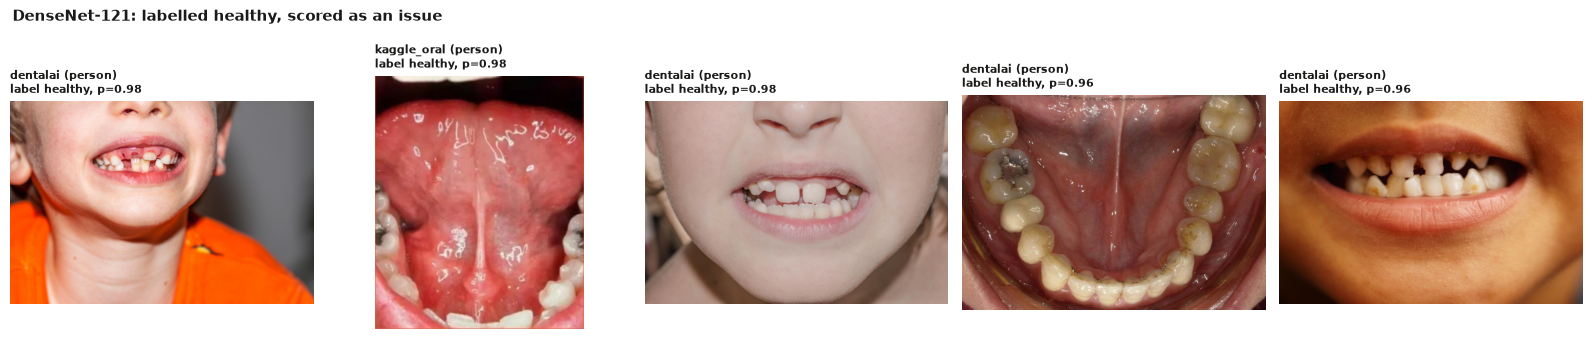

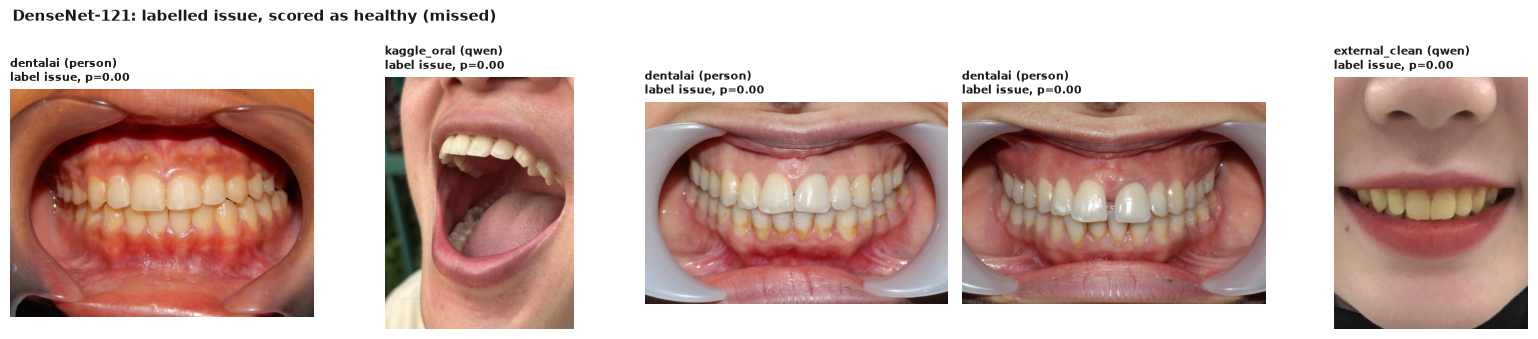

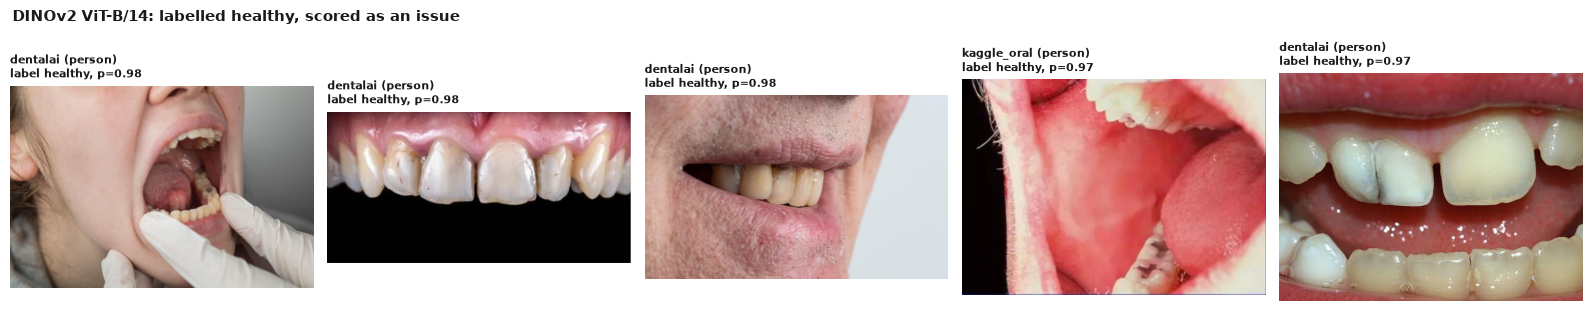

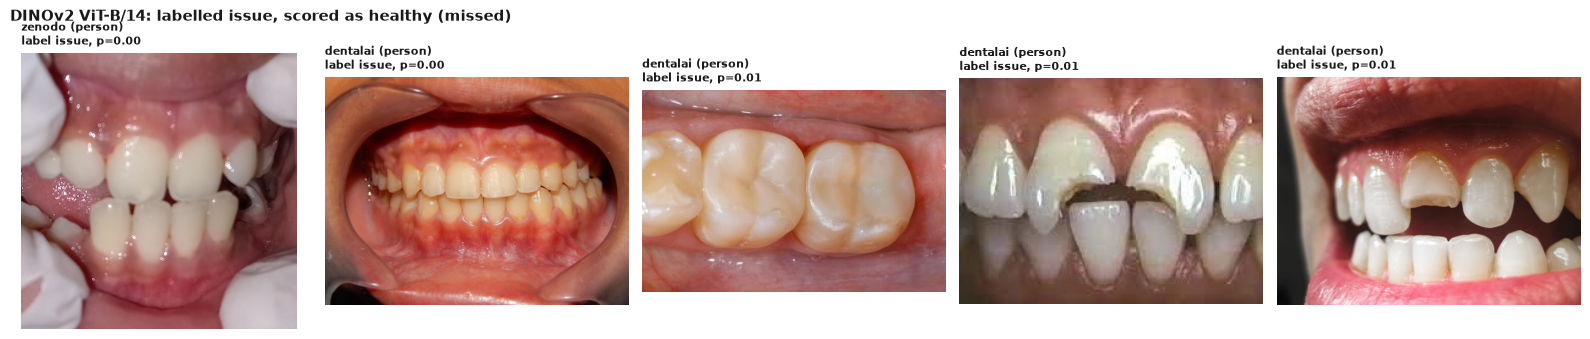

In [8]:
def show_row(frame, title):
    fig, ax = plt.subplots(1, len(frame), figsize=(3.2 * len(frame), 3.4))
    for a_, r in zip(np.atleast_1d(ax), frame.itertuples()):
        im = Image.open(DATA / r.image); im.draft("RGB", (400, 400))
        a_.imshow(im.convert("RGB")); a_.axis("off")
        a_.set_title(f"{r.dataset} ({r.label_by.split()[0]})\nlabel {'issue' if getattr(r, TARGET) else 'healthy'}, p={r.p_issue:.2f}", fontsize=8)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold"); plt.tight_layout(); plt.show()

for a, m in runs.items():
    p = pd.concat([pd.read_csv(RESULTS / a / f) for f in ("test_predictions.csv", "xsrc_test_predictions.csv")])
    show_row(p[p[TARGET] == 0].nlargest(5, "p_issue"), f"{m['name']}: labelled healthy, scored as an issue")
    show_row(p[p[TARGET] == 1].nsmallest(5, "p_issue"), f"{m['name']}: labelled issue, scored as healthy (missed)")

## 9. Grad-CAM: where does each model look?

Red = the areas that pushed the "has an issue" score up most. Heat on teeth and gums is what we want; heat on lips,
background, borders or image corners would mean the model learned the photo style (section 4). For DenseNet the map comes
from its last convolutional features (7x7), for DINOv2 from its patch tokens (16x16 patches of 14 px), so the DINOv2
map is finer. Gradient maps on a ViT are noisier than on a CNN, so read the DINOv2 row as a hint, not proof.

Using cache found in C:\Users\aiden/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\aiden/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\aiden/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\aiden/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


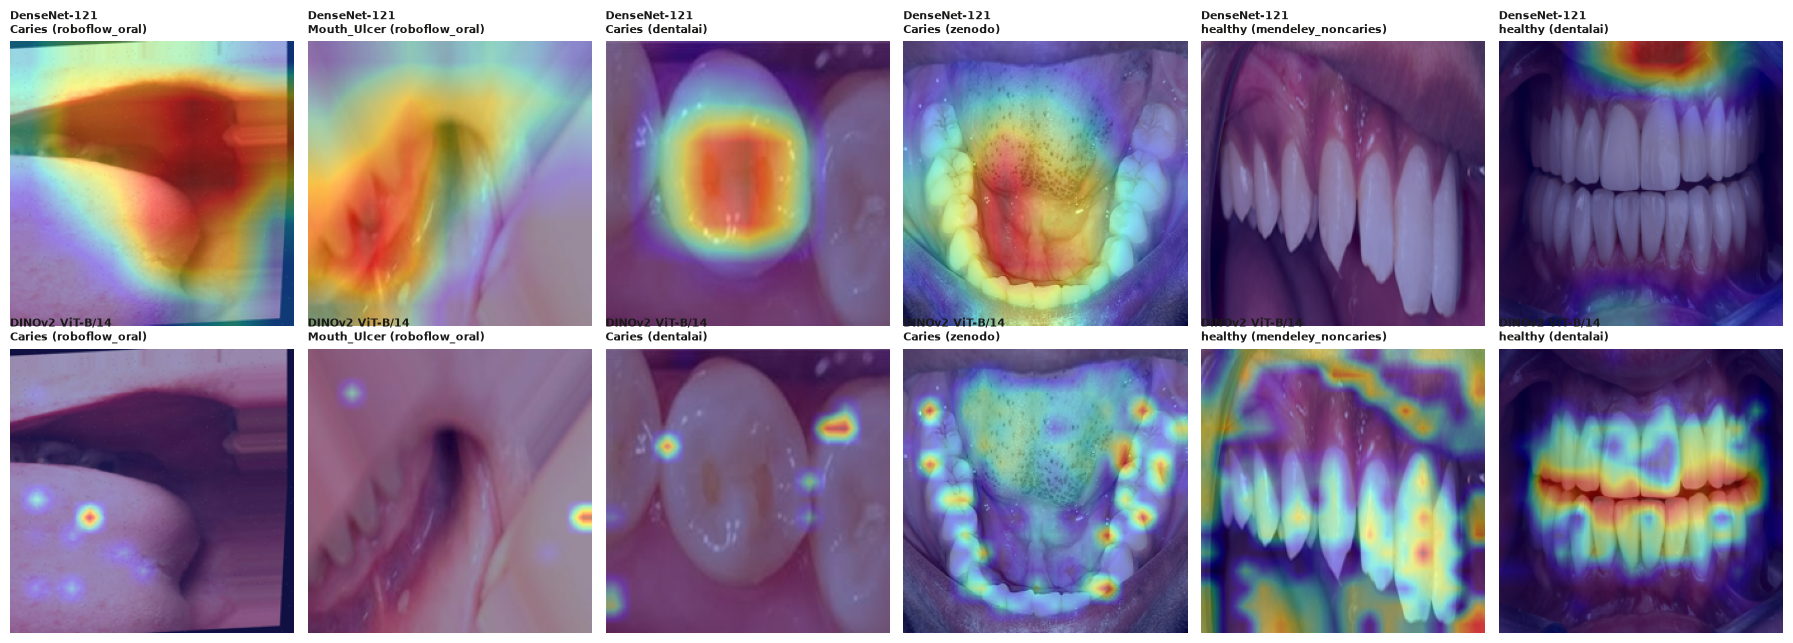

In [9]:
DEV = "cuda" if torch.cuda.is_available() else "cpu"

def cam(net, x):
    if net.arch == "densenet121":
        feats = torch.relu(net.body.features(x))                       # B, C, 7, 7
        out = net.head(feats.mean((2, 3)))
        grad, = torch.autograd.grad(out[0, 0], feats)
        c = torch.relu((grad.mean((2, 3), keepdim=True) * feats).sum(1))[0]
    else:
        t = net.body.forward_features(x)
        tok = t["x_norm_patchtokens"]                                  # B, 256, D
        out = net.head(torch.cat([t["x_norm_clstoken"], tok.mean(1)], 1))
        grad, = torch.autograd.grad(out[0, 0], tok)
        s = int(tok.shape[1] ** 0.5)
        c = torch.relu((grad.mean(1, keepdim=True) * tok).sum(-1))[0].reshape(s, s)
    c = (c - c.min()) / (c.max() - c.min() + 1e-8)
    return c.detach().cpu().numpy()

p0 = pd.read_csv(RESULTS / "densenet121" / "test_predictions.csv")
x0 = pd.read_csv(RESULTS / "densenet121" / "xsrc_test_predictions.csv")
pick = pd.concat([p0[p0[c] == 1].sample(1, random_state=1) for c in ["Caries", "Mouth_Ulcer"]]           # Roboflow issues
                 + [x0[(x0[TARGET] == 1) & (x0.dataset == d)].sample(1, random_state=1) for d in ["dentalai", "zenodo"]]
                 + [x0[(x0[TARGET] == 0) & (x0.dataset == d)].sample(1, random_state=1) for d in ["mendeley_noncaries", "dentalai"]])
fig, ax = plt.subplots(len(runs), len(pick), figsize=(3 * len(pick), 3.2 * len(runs)), squeeze=False)
for i, (a, m) in enumerate(runs.items()):
    ck, nets, _ = multilabel.load_model(RESULTS / a / "model.pt", DEV)
    tf = multilabel.eval_tf(ck["img_size"])
    for j, r in enumerate(pick.itertuples()):
        im = Image.open(DATA / r.image).convert("RGB").resize((ck["img_size"], ck["img_size"]))
        c = cam(nets[0], tf(im).unsqueeze(0).to(DEV))
        ax[i, j].imshow(im); ax[i, j].imshow(np.array(Image.fromarray(np.uint8(c * 255)).resize(im.size, Image.BILINEAR)),
                                             cmap="jet", alpha=0.4)
        lab = ", ".join(k for k in CONDITIONS if getattr(r, k)) or "healthy"
        ax[i, j].set_title(f"{m['name']}\n{lab} ({r.dataset})", fontsize=8); ax[i, j].axis("off")
    del nets; torch.cuda.empty_cache()
plt.tight_layout(); plt.show()

## 10. Experiment log and decision

In [10]:
log = pd.DataFrame([{"model": m["name"], "epochs": m["settings"]["epochs"], "lr": m["settings"]["lr"], "img": m["settings"]["img"],
                     "train images": m["n_train"], "clean test AUROC": round(m["auroc"], 4), "sensitivity": round(m["sensitivity"], 3),
                     "specificity": round(m["specificity"], 3), "cross-source AUROC": round(m["xsrc_test"]["auroc"], 4),
                     "full-test AUROC": round(m["full_test"]["auroc"], 4)} for m in runs.values()])
display(log)

,model,epochs,lr,img,train images,clean test AUROC,sensitivity,specificity,cross-source AUROC,full-test AUROC
0,DenseNet-121,10,0.00010,224,25524,0.9946,0.989,0.960,0.9798,0.9944
1,DINOv2 ViT-B/14,10,0.00002,224,25524,0.9957,0.989,0.972,0.9839,0.9953


| Run | What changed | Why | Result (clean test) | Notes |
|---|---|---|---|---|
| gate v1 | DenseNet-121 vs DINOv2 ViT-B/14, 10 epochs, threshold catches 95% of clean-val issues | first binary gate on oral_dataset (first release, 37,913 images) | AUROC DenseNet 0.9953, DINOv2 0.9925; sensitivity 94.9% / 94.4% | clean test is one source per class (section 4); no cross-source test yet |
| gate v2 | Daniel's cleaned release (33,843 images: unchecked "healthy" zenodo photos dropped); train without the cross-source sets; threshold on clean val + cross-source val | v1 data had ~3,400 unchecked "healthy" photos; its clean test couldn't separate disease from photo style | see the table above | first run scored on Daniel's xsrc_test, so directly comparable with his gate |
| tuning (DenseNet) | backbone lr 5e-5 / 2e-4 (base 1e-4); colour jitter 0.4 (base 0.2). `train.py --tag`, results in `results/Aiden/tuning/` | is the gate limited by its training settings? | cross-source **val** AUROC 0.9818 / 0.9811 / 0.9808 vs base 0.9801 (test: 0.9785 / 0.9818 / 0.9781 vs 0.9798) | all within ~0.002, inside the confidence interval: settings are not the bottleneck, the data is (within-source AUROC stays ~0.90 on dentalai). Base kept; picking on test would leak |
| YOLO11n 100 epochs | 40 -> 100 epochs, patience 20 | at 40 epochs clean-val mAP was still rising | Daniel's full test mAP50 0.798 -> 0.829; clean test 0.697 -> 0.752 (Calculus 0.40 -> 0.51, Hypodontia 0.53 -> 0.63) | best epoch was 100, still rising slowly; yolo11s is the next step |
| | | | | |

**Decision (fill in, then copy to `docs/decisions.md`):** which model is the gate, and why. Points to weigh: AUROC and
sensitivity on the clean test; the **cross-source AUROC and the within-source AUROCs** (section 7), which say which
model recognises disease rather than photo style; how close each is to Daniel's gate; size (DenseNet is about 10x smaller
and faster, which matters for a phone or a free-tier server); Grad-CAM (section 9) for which looks at the mouth.